# **Multi-PDF Chatbot Using Retrieval-Augmented Generation (RAG) and Streamlit**

https://drive.google.com/drive/folders/1WBAFIZYcAJ757Nn1jZuZYp4WuLWeiyhX?usp=sharing

Imagine you have 10 PDF documents, each containing 100 pages. You need to find the answer to one specific question. Would you open every PDF, search through hundreds of pages, and read everything manually? 🤔

What if you could simply upload all your PDFs, ask a question in plain English, and get an answer based on their content within seconds?

That is exactly what we are going to build!

**2. Project Goal**

The goal of this project is to develop an AI-powered Multi-PDF Chatbot using Retrieval-Augmented Generation (RAG) and Streamlit that enables users to upload multiple PDF documents and ask questions about their content through a simple interactive interface.

The system uses Gemini embeddings to convert document chunks into vectors, FAISS to retrieve relevant information, and a Groq-hosted LLM to generate answers based on the retrieved context.

**3. Key Objectives**
1. Allow users to upload multiple PDF documents.
2. Extract text and split it into manageable chunks.
3. Generate vector embeddings using Gemini.
4. Store and retrieve relevant document chunks using FAISS.
5. Generate context-aware answers using Groq.
6. Build a user-friendly chatbot interface using Streamlit.

**4. Expected Outcome**

A working web application that allows users to interact conversationally with multiple PDF documents, find relevant information quickly, and receive answers grounded in the retrieved document content.

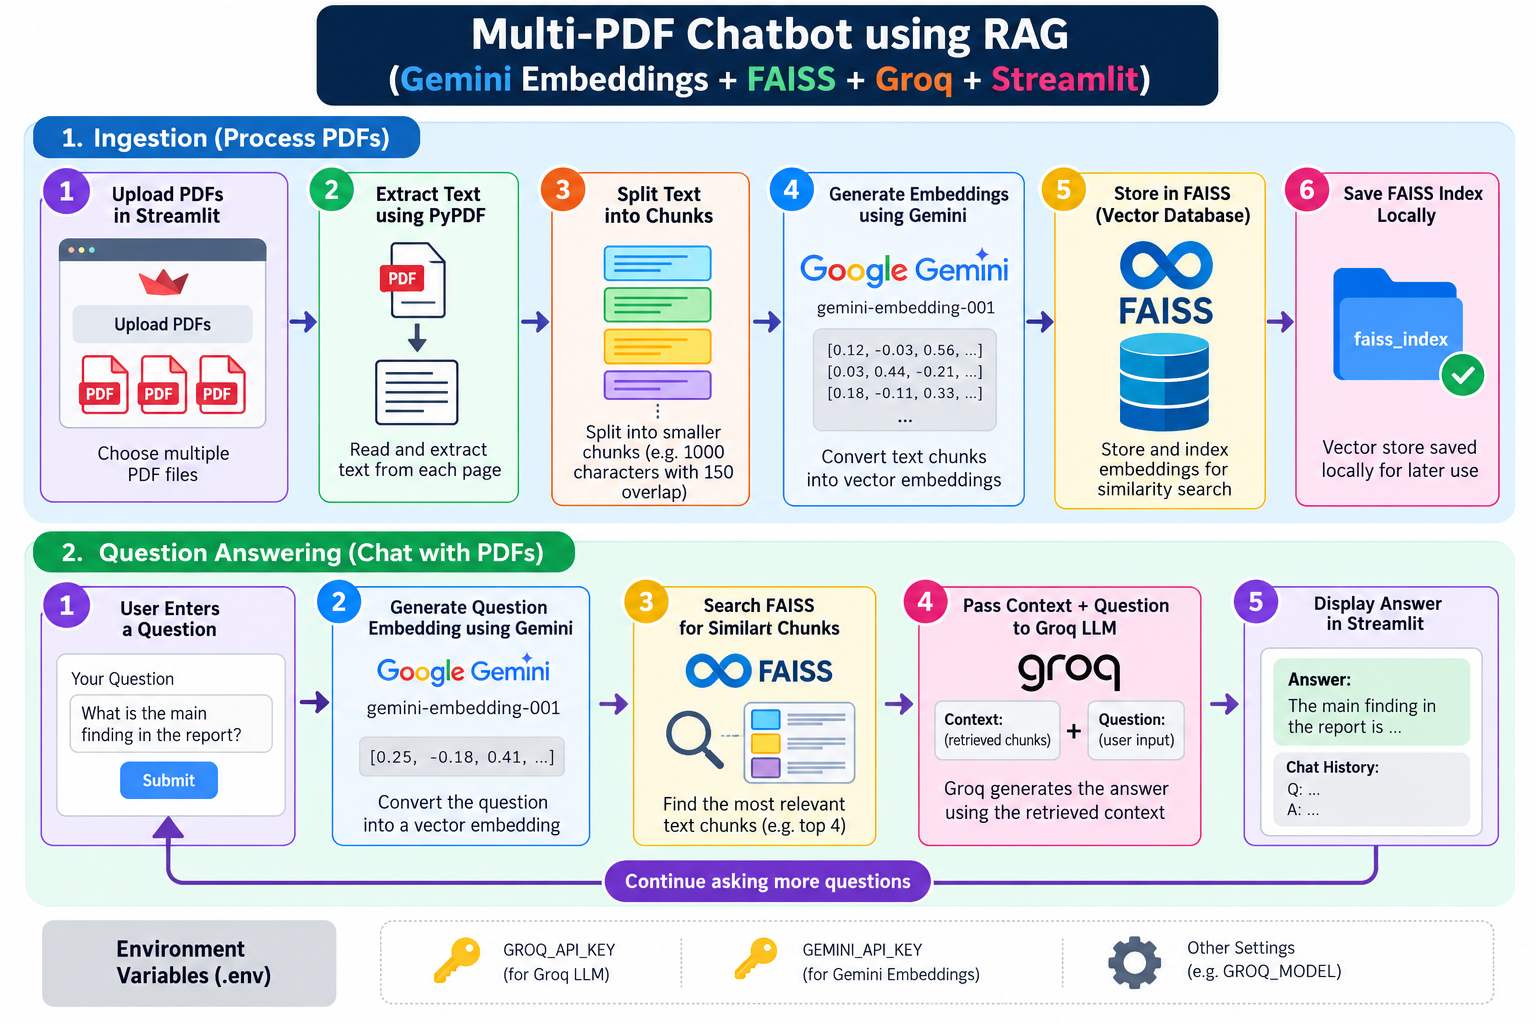

**Steps to Build Multi-PDF Chatbot Using RAG and Streamlit in VS Code**

**Step 1: Create the project**

Open VS Code → File → Open Folder → create or select a folder named multi_pdf_rag.

**Step 2: Create a virtual environment**

Open Terminal → New Terminal.

Run these commands one by one:

In [ ]:
# mac
python3 -m venv .venv
source .venv/bin/activate

In [ ]:
# windows
python -m venv venv
.\.venv\Scripts\Activate.ps1

# mac
python3 -m venv .venv
source .venv/bin/activate

**Step 3: Add dependencies to requirements.txt**

In [ ]:
streamlit
python-dotenv
pypdf
langchain-core
langchain-classic
langchain-community
langchain-text-splitters
langchain-google-genai
langchain-groq
faiss-cpu

In [ ]:
# save file and run
pip install -r requirements.txt

**Step 4: Configure API keys**

Create .env in the project root and add:

In [ ]:
GOOGLE_API_KEY=your_gemini_api_key
GROQ_API_KEY=your_groq_api_key

**Step 5: Add the chatbot code**

create app.py and add code


In [ ]:

# Import necessary libraries
import os
import streamlit as st
from dotenv import load_dotenv
from pypdf import PdfReader

from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_google_genai import GoogleGenerativeAIEmbeddings
from langchain_groq import ChatGroq
from langchain_community.vectorstores import FAISS
from langchain_classic.chains.question_answering import load_qa_chain
from langchain_core.prompts import PromptTemplate

# Load API keys
load_dotenv()

GROQ_API_KEY = os.getenv("GROQ_API_KEY")
GEMINI_API_KEY = os.getenv("GEMINI_API_KEY") or os.getenv("GOOGLE_API_KEY")

if not GROQ_API_KEY:
    st.error("Please add GROQ_API_KEY to your .env file.")
    st.stop()

if not GEMINI_API_KEY:
    st.error("Please add GEMINI_API_KEY to your .env file.")
    st.stop()


# Extract text from PDFs
def get_pdf_text(uploaded_files):
    text = ""

    for file in uploaded_files:
        pdf_reader = PdfReader(file)

        for page in pdf_reader.pages:
            text += page.extract_text() or ""

    return text


# Split text into chunks
def get_text_chunks(text):
    splitter = RecursiveCharacterTextSplitter(
        chunk_size=1000,
        chunk_overlap=150
    )

    return splitter.split_text(text)


# Create Gemini embeddings
@st.cache_resource
def get_embeddings():
    return GoogleGenerativeAIEmbeddings(
        model="gemini-embedding-001",
        google_api_key=GEMINI_API_KEY
    )


# Create FAISS vector store
def get_vector_store(text_chunks):
    embeddings = get_embeddings()

    vector_store = FAISS.from_texts(
        texts=text_chunks,
        embedding=embeddings
    )

    vector_store.save_local("faiss_index")

    return vector_store


# Create question-answering chain WITH MEMORY
def get_conversational_chain():
    prompt_template = """
    You are a helpful PDF assistant.

    Use the conversation history to understand follow-up questions.
    Answer using the retrieved PDF context.
    If the answer is not available in the context, say:
    "Answer is not available in the context."

    Conversation History:
    {chat_history}

    PDF Context:
    {context}

    Current Question:
    {question}

    Answer:
    """

    model = ChatGroq(
        model=os.getenv("GROQ_MODEL", "openai/gpt-oss-120b"),
        temperature=0.3,
        api_key=GROQ_API_KEY
    )

    prompt = PromptTemplate(
        template=prompt_template,
        input_variables=["context", "question", "chat_history"]
    )

    return load_qa_chain(
        model,
        chain_type="stuff",
        prompt=prompt
    )


# Chat with PDFs using conversation memory
def chat_with_pdf(question):
    embeddings = get_embeddings()

    db = FAISS.load_local(
        "faiss_index",
        embeddings,
        allow_dangerous_deserialization=True
    )

    # Retrieve relevant PDF chunks
    docs = db.similarity_search(question, k=4)

    # MEMORY: Get the last 5 question-answer pairs
    previous_messages = st.session_state.history[-5:]

    chat_history = ""

    for old_question, old_answer in previous_messages:
        chat_history += f"User: {old_question}\n"
        chat_history += f"Assistant: {old_answer}\n"

    # Generate answer using PDF context and conversation history
    chain = get_conversational_chain()

    result = chain.invoke({
        "input_documents": docs,
        "question": question,
        "chat_history": chat_history
    })

    return result["output_text"]


# Streamlit interface
st.title("💬 Multi-PDF Chatbot Using RAG and Streamlit")
st.caption("Gemini Embeddings | FAISS | Groq | Conversation Memory")

with st.sidebar:
    st.header("📄 Upload PDFs")

    uploaded_files = st.file_uploader(
        "Choose PDF files",
        type=["pdf"],
        accept_multiple_files=True
    )

    if st.button("Process PDFs"):
        if not uploaded_files:
            st.warning("Please upload at least one PDF.")
        else:
            try:
                with st.spinner("Processing PDFs..."):
                    raw_text = get_pdf_text(uploaded_files)

                    if not raw_text.strip():
                        st.error("No readable text found in the PDFs.")
                    else:
                        chunks = get_text_chunks(raw_text)
                        get_vector_store(chunks)

                        st.session_state["pdf_processed"] = True
                        st.session_state.history = []

                        st.success(
                            f"Successfully processed {len(chunks)} chunks!"
                        )

            except Exception as error:
                st.error(f"PDF processing failed: {error}")


# Initialize conversation memory
if "history" not in st.session_state:
    st.session_state.history = []

st.header("Ask Questions About Your PDFs")

# Display previous conversation
for q, a in st.session_state.history:
    st.markdown(f"**You:** {q}")
    st.markdown(f"**Assistant:** {a}")

question = st.text_input(
    "Your Question",
    key="current_question"
)

if st.button("Submit") and question.strip():
    if not st.session_state.get("pdf_processed", False):
        st.warning("Please upload and process your PDFs first.")
    else:
        try:
            with st.spinner("Thinking..."):
                answer = chat_with_pdf(question)

            # Save the new conversation in memory
            st.session_state.history.append((question, answer))

            # Clear the input and refresh the interface
            st.rerun()

        except Exception as error:
            st.error(f"Could not generate answer: {error}")

# Clear conversation memory
if st.button("Clear Chat History"):
    st.session_state.history = []
    st.rerun()


In [ ]:
#Run the project
#In the VS Code terminal:
streamlit run app.py